# Schritt 2: Gemeindedaten, Integration und Zuordnung der Restaurants

Dieses Notebook
- lädt die Gemeindegrenzen der Schweiz (swissBOUNDARIES3D, Stand Januar 2026) inklusive Einwohnerzahl pro Gemeinde,
- gleicht den Gemeindestand mit dem BFS-Gemeindeverzeichnis ab,
- ordnet jedes Restaurant über einen **räumlichen Join** (Punkt in Gemeinde) einer Gemeinde zu,
- berechnet pro Gemeinde die Anzahl veganer Restaurants und die Dichte pro 1000 Einwohner,
- speichert alles in SQLite (Tabellen `municipalities`, `restaurants`, `integration_log`) und zeigt eine erste Karte.

Jeder Integrationsschritt wird mit Anzahl Datensätzen protokolliert (verlangt in der Aufgabenstellung: Schlüsselabgleich, Joins, verlorene/gewonnene Datensätze).

Voraussetzung: Notebook 01 wurde ausgeführt (`data/processed/vegan_restaurants_ch.csv` existiert).

In [5]:
%pip install geopandas pyogrio matplotlib
import sqlite3
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.



  Using cached geopandas-1.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached pyogrio-0.13.0-cp311-abi3-win_amd64.whl.metadata (6.0 kB)
Using cached geopandas-1.2.0-py3-none-any.whl (368 kB)
Using cached pyogrio-0.13.0-cp311-abi3-win_amd64.whl (23.8 MB)
   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.7 MB ? eta -:--:--
   --- ------------------------------------ 0.5/6.7 MB 1.5 MB/s eta 0:00:05
   ------ --------------------------------- 1.0/6.7 MB 1.8 MB/s eta 0:00:04
   ------- -------------------------------- 1.3/6.7 MB 1.9 MB/s eta 0:00:03
   ---------- ----------------------------- 1.8/6.7 MB 2.0 MB/s eta 0:00:03
   -------------- ------------------------- 2.4/6.7 MB 2.1 MB/s eta 0:00:03
   ----------------- ---------------------- 2.9/6.7 MB 2.1 MB/s eta 0:00:02
   -------------------- ------------------- 3.4/6.7 MB 2.1 MB/s eta 0:00:02
   --------------------- ------------------ 3.7/6.7 MB 2.2 MB/s eta 0:00

## Pfade und Integrationsprotokoll

In [6]:
GRENZEN_ZIP = '../data/raw/swissboundaries3d_2026-01_2056_5728.gdb.zip'
VERZEICHNIS_CSV = '../data/raw/gemeindeverzeichnis_bfs.csv'
RESTAURANTS_CSV = '../data/processed/vegan_restaurants_ch.csv'
DB_PATH = '../data/processed/vegan_project.db'

integration_log = []

def log(schritt, beschreibung, anzahl):
    integration_log.append({'schritt': schritt, 'beschreibung': beschreibung, 'anzahl': int(anzahl)})
    print(f'[{schritt}] {beschreibung}: {int(anzahl)}')

## 1. Gemeindegrenzen laden (swisstopo, swissBOUNDARIES3D)

Der Layer `TLM_HOHEITSGEBIET` enthält neben den politischen Gemeinden auch Seen (`OBJEKTART = 1`), gemeindefreie Gebiete (`OBJEKTART = 2`) sowie Gebiete von Liechtenstein, Deutschland (Büsingen) und Italien (Campione). Für die Analyse behalten wir nur die **Gemeindegebiete der Schweiz** (`ICC = CH`, `OBJEKTART = 0`).
Die Datei enthält zusätzlich die Einwohnerzahl (`EINWOHNERZAHL`), die wir als Nenner für die Dichte pro 1000 Einwohner verwenden.

In [7]:
raw = gpd.read_file(GRENZEN_ZIP, layer='TLM_HOHEITSGEBIET')
log('1', 'Hoheitsgebiete in swissBOUNDARIES3D (roh)', len(raw))

gem = raw[(raw['ICC'] == 'CH') & (raw['OBJEKTART'] == 0)].copy()
log('1', 'davon Gemeindegebiete der Schweiz (ICC = CH, OBJEKTART = 0)', len(gem))

# 3D-Geometrie auf 2D reduzieren, Koordinatensystem LV95 (EPSG:2056) setzen
gem['geometry'] = gem.geometry.force_2d()
gem = gem.set_crs(2056, allow_override=True)

gem = gem[['BFS_NUMMER', 'NAME', 'KANTONSNUMMER', 'BEZIRKSNUMMER', 'GEM_FLAECHE', 'EINWOHNERZAHL', 'geometry']].rename(columns={
    'BFS_NUMMER': 'bfs_nummer', 'NAME': 'name', 'KANTONSNUMMER': 'kanton_nr', 'BEZIRKSNUMMER': 'bezirk_nr',
    'GEM_FLAECHE': 'flaeche_ha', 'EINWOHNERZAHL': 'einwohner'})
gem['bfs_nummer'] = gem['bfs_nummer'].astype(int)

print('Einwohner total:', int(gem['einwohner'].sum()))
print('Gemeinden ohne Einwohner:', int((gem['einwohner'] == 0).sum()))
gem.head()

[1] Hoheitsgebiete in swissBOUNDARIES3D (roh): 2136
[1] davon Gemeindegebiete der Schweiz (ICC = CH, OBJEKTART = 0): 2110
Einwohner total: 9051029
Gemeinden ohne Einwohner: 0


,bfs_nummer,name,kanton_nr,bezirk_nr,flaeche_ha,einwohner,geometry
0,131,Adliswil,1.0,106.0,777,19893,"MULTIPOLYGON (((2682588.433 1239418.954, 26825..."
1,3714,Rheinwald,18.0,1851.0,13681,570,"MULTIPOLYGON (((2747636.177 1152720.387, 27476..."
2,5722,Grens,22.0,2228.0,256,391,"MULTIPOLYGON (((2505186.356 1139817.844, 25051..."
3,6730,Val Terbi,26.0,2601.0,4669,3270,"MULTIPOLYGON (((2602713.788 1239572.35, 260270..."
4,4123,Windisch,19.0,1904.0,491,8153,"MULTIPOLYGON (((2659073.266 1256864.692, 26590..."


## 2. Abgleich des Gemeindestands mit dem BFS-Gemeindeverzeichnis

Alle Quellen müssen denselben Gemeindestand haben (Gemeindefusionen!). Wir prüfen, ob die BFS-Nummern der Grenzdatei exakt den aktuellen Gemeinden im Verzeichnis entsprechen (`Level = 3`, kein `ValidTo`).

In [8]:
verz = pd.read_csv(VERZEICHNIS_CSV, dtype=str)
aktuell = verz[(verz['Level'] == '3') & (verz['ValidTo'].isna())]
log('2', 'aktuelle Gemeinden im BFS-Gemeindeverzeichnis', len(aktuell))

codes_grenzen = set(gem['bfs_nummer'])
codes_verz = set(aktuell['BfsCode'].astype(int))
log('2', 'BFS-Nummern in Grenzdatei, aber nicht im Verzeichnis', len(codes_grenzen - codes_verz))
log('2', 'BFS-Nummern im Verzeichnis, aber nicht in Grenzdatei', len(codes_verz - codes_grenzen))

[2] aktuelle Gemeinden im BFS-Gemeindeverzeichnis: 2110
[2] BFS-Nummern in Grenzdatei, aber nicht im Verzeichnis: 0
[2] BFS-Nummern im Verzeichnis, aber nicht in Grenzdatei: 0


## 3. Restaurants laden und Gemeinden zuordnen (räumlicher Join)

Die Restaurants haben Koordinaten in WGS84 (EPSG:4326). Sie werden nach LV95 (EPSG:2056) umgerechnet und per `within` der Gemeinde zugeordnet, in der der Punkt liegt. Ortsangaben aus OSM (`city`) werden bewusst nicht verwendet, weil sie bei über einem Drittel der Einträge fehlen.

In [9]:
r = pd.read_csv(RESTAURANTS_CSV, dtype={'postcode': str})
log('3', 'Restaurants aus OpenStreetMap', len(r))

pts = gpd.GeoDataFrame(r, geometry=gpd.points_from_xy(r['lon'], r['lat']), crs='EPSG:4326').to_crs(2056)
joined = gpd.sjoin(pts, gem[['bfs_nummer', 'geometry']], how='left', predicate='within').drop(columns='index_right')

log('3', 'Restaurants einer Gemeinde zugeordnet', joined['bfs_nummer'].notna().sum())
log('3', 'Restaurants ohne Gemeinde (z. B. im See oder ausserhalb der Schweiz)', joined['bfs_nummer'].isna().sum())
log('3', 'doppelt zugeordnete Restaurants (Prüfung, soll 0 sein)', joined.duplicated(['osm_type', 'osm_id']).sum())

[3] Restaurants aus OpenStreetMap: 709
[3] Restaurants einer Gemeinde zugeordnet: 709
[3] Restaurants ohne Gemeinde (z. B. im See oder ausserhalb der Schweiz): 0
[3] doppelt zugeordnete Restaurants (Prüfung, soll 0 sein): 0


## 4. Pro Gemeinde aggregieren

Mit `how='left'` bleiben auch Gemeinden ohne Restaurant erhalten (Anzahl 0). Dichte = Anzahl Restaurants / Einwohner × 1000.

In [10]:
anz = joined.groupby('bfs_nummer').agg(
    n_restaurants=('osm_id', 'size'),
    n_vegan_only=('vegan_only', 'sum')).reset_index()

gem_stat = gem.merge(anz, on='bfs_nummer', how='left')
gem_stat[['n_restaurants', 'n_vegan_only']] = gem_stat[['n_restaurants', 'n_vegan_only']].fillna(0).astype(int)
gem_stat['dichte_pro_1000'] = gem_stat['n_restaurants'] / gem_stat['einwohner'] * 1000

log('4', 'Gemeinden mit mindestens einem Restaurant', (gem_stat['n_restaurants'] > 0).sum())
log('4', 'Gemeinden ohne Restaurant', (gem_stat['n_restaurants'] == 0).sum())
log('4', 'Restaurants total in der Gemeindetabelle (Kontrolle)', gem_stat['n_restaurants'].sum())

[4] Gemeinden mit mindestens einem Restaurant: 158
[4] Gemeinden ohne Restaurant: 1952
[4] Restaurants total in der Gemeindetabelle (Kontrolle): 709


## 5. In SQLite speichern und per SQL abfragen

Die Tabelle `restaurants` wird um die Spalte `bfs_nummer` ergänzt (ersetzt die Tabelle aus Notebook 01). Die Gemeindetabelle `municipalities` enthält keine Geometrie (die liegt in der GeoPackage-Datei).

In [11]:
rest_tab = pd.DataFrame(joined.drop(columns='geometry'))
muni_tab = pd.DataFrame(gem_stat.drop(columns='geometry'))

with sqlite3.connect(DB_PATH) as conn:
    rest_tab.to_sql('restaurants', conn, if_exists='replace', index=False)
    muni_tab.to_sql('municipalities', conn, if_exists='replace', index=False)

    query = """
    SELECT m.bfs_nummer, m.name, m.einwohner,
           COUNT(r.osm_id) AS n_restaurants,
           ROUND(1000.0 * COUNT(r.osm_id) / m.einwohner, 3) AS dichte_pro_1000
    FROM municipalities m
    LEFT JOIN restaurants r ON r.bfs_nummer = m.bfs_nummer
    GROUP BY m.bfs_nummer
    ORDER BY n_restaurants DESC
    LIMIT 10
    """
    top10 = pd.read_sql(query, conn)

    total_sql = pd.read_sql('SELECT COUNT(*) AS n FROM restaurants WHERE bfs_nummer IS NOT NULL', conn)['n'][0]

log('5', 'Restaurants mit Gemeinde in SQLite (Kontrolle per SQL)', total_sql)
top10

[5] Restaurants mit Gemeinde in SQLite (Kontrolle per SQL): 709


,bfs_nummer,name,einwohner,n_restaurants,dichte_pro_1000
0,261,Zürich,436551,190,0.435
1,351,Bern,137995,62,0.449
2,2701,Basel,177571,51,0.287
3,5586,Lausanne,144873,29,0.200
4,230,Winterthur,120376,27,0.224
5,1061,Luzern,86234,23,0.267
6,6621,Genève,209061,17,0.081
7,3203,St. Gallen,78863,13,0.165
8,5890,Vevey,20142,12,0.596
9,371,Biel/Bienne,56896,9,0.158


## 6. Erste Übersicht

In [12]:
print('Gemeinden total:', len(gem_stat))
print('Anteil Gemeinden ohne Restaurant: {:.1%}'.format((gem_stat['n_restaurants'] == 0).mean()))
print()
print('Verteilung der Anzahl Restaurants pro Gemeinde:')
print(gem_stat['n_restaurants'].describe())
print()
print('Top 10 nach Dichte (nur Gemeinden mit mindestens 2000 Einwohnern):')
gem_stat[gem_stat['einwohner'] >= 2000].nlargest(10, 'dichte_pro_1000')[['name', 'einwohner', 'n_restaurants', 'dichte_pro_1000']]

Gemeinden total: 2110
Anteil Gemeinden ohne Restaurant: 92.5%

Verteilung der Anzahl Restaurants pro Gemeinde:
count    2110.000000
mean        0.336019
std         4.665317
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       190.000000
Name: n_restaurants, dtype: float64

Top 10 nach Dichte (nur Gemeinden mit mindestens 2000 Einwohnern):


,name,einwohner,n_restaurants,dichte_pro_1000
1684,Flims,2902,3,1.033770
1271,Grindelwald,3930,4,1.017812
1358,Zermatt,6099,5,0.819807
1153,Selzach,3690,3,0.813008
1828,Surses,2465,2,0.811359
1965,Wildhaus-Alt St. Johann,2601,2,0.768935
1198,Schwende-Rüte,6108,4,0.654879
178,Vevey,20142,12,0.595770
1626,Adelboden,3420,2,0.584795
2010,Interlaken,6123,3,0.489956


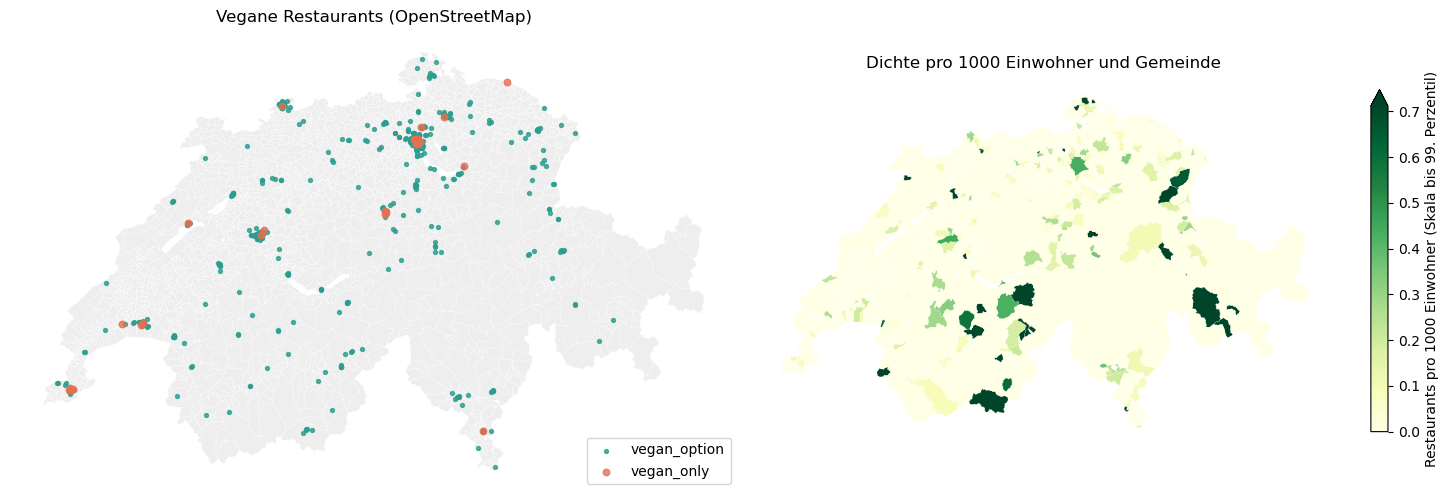

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

gem_stat.plot(ax=axes[0], color='#eeeeee', edgecolor='white', linewidth=0.2)
farben = {'vegan_option': '#2a9d8f', 'vegan_only': '#e76f51'}
for kat, farbe in farben.items():
    sub = joined[joined['vegan_category'] == kat]
    sub.plot(ax=axes[0], color=farbe, markersize=8 if kat == 'vegan_option' else 22, label=kat, alpha=0.8)
axes[0].set_title('Vegane Restaurants (OpenStreetMap)')
axes[0].legend(loc='lower right')
axes[0].set_axis_off()

vmax = gem_stat['dichte_pro_1000'].quantile(0.99)
gem_stat.plot(ax=axes[1], column='dichte_pro_1000', cmap='YlGn', vmin=0, vmax=vmax, edgecolor='white', linewidth=0.1,
              legend=True, legend_kwds={'label': 'Restaurants pro 1000 Einwohner (Skala bis 99. Perzentil)', 'shrink': 0.6})
axes[1].set_title('Dichte pro 1000 Einwohner und Gemeinde')
axes[1].set_axis_off()

plt.tight_layout()
plt.savefig('../figures/karte_dichte_uebersicht.png', dpi=150)
plt.show()

## 7. Ergebnisse speichern (Gemeindekarte und Integrationsprotokoll)

In [14]:
# Für Karten reicht eine vereinfachte Geometrie (50 m); der räumliche Join oben nutzt die genauen Grenzen.
gem_karte = gem_stat.copy()
gem_karte['geometry'] = gem_karte.geometry.simplify(50, preserve_topology=True)
gem_karte.to_file('../data/processed/gemeinden_2026.gpkg', layer='gemeinden', driver='GPKG')

protokoll = pd.DataFrame(integration_log)
protokoll.to_csv('../data/processed/integration_log.csv', index=False, encoding='utf-8')
with sqlite3.connect(DB_PATH) as conn:
    protokoll.to_sql('integration_log', conn, if_exists='replace', index=False)
protokoll

,schritt,beschreibung,anzahl
0,1,Hoheitsgebiete in swissBOUNDARIES3D (roh),2136
1,1,"davon Gemeindegebiete der Schweiz (ICC = CH, O...",2110
2,2,aktuelle Gemeinden im BFS-Gemeindeverzeichnis,2110
3,2,"BFS-Nummern in Grenzdatei, aber nicht im Verze...",0
4,2,"BFS-Nummern im Verzeichnis, aber nicht in Gren...",0
5,3,Restaurants aus OpenStreetMap,709
6,3,Restaurants einer Gemeinde zugeordnet,709
7,3,Restaurants ohne Gemeinde (z. B. im See oder a...,0
8,3,"doppelt zugeordnete Restaurants (Prüfung, soll...",0
9,4,Gemeinden mit mindestens einem Restaurant,158
